In [225]:
import pandas as pd
import numpy as np

In [226]:
#importação
df = pd.read_csv('insurance.csv')

In [227]:
#começar a limpeza do df
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [228]:
print('Duplicadas:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicadas: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [229]:
df = df.drop_duplicates()
df.shape

(1337, 7)

In [230]:
df.sex = df.sex.map({'female': 0, 'male': 1})
df.smoker = df.smoker.map({'no': 0, 'yes': 1})
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520


In [231]:
df = pd.get_dummies(df, columns=['region'], drop_first=True, dtype=int)
df.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,1
1,18,1,33.770,1,0,1725.55230,0,1,0
2,28,1,33.000,3,0,4449.46200,0,1,0
3,33,1,22.705,0,0,21984.47061,1,0,0
4,32,1,28.880,0,0,3866.85520,1,0,0


In [232]:
df.shape
df.dtypes
df.isnull().sum()

age                 0
sex                 0
bmi                 0
children            0
smoker              0
charges             0
region_northwest    0
region_southeast    0
region_southwest    0
dtype: int64

In [233]:
#analisar as variaveis em grafico

import plotly.express as px

boxplot = px.box(df, y='age')
boxplot.show()

In [234]:
import plotly.express as px

boxplot = px.box(df, y='bmi')
boxplot.show()

In [235]:
import plotly.express as px

boxplot = px.box(df, y='children')
boxplot.show()

In [236]:
import plotly.express as px

boxplot = px.box(df, y='charges')
boxplot.show()

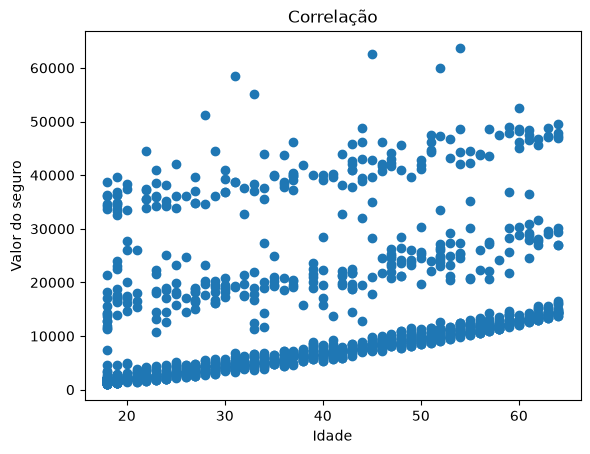

In [237]:
#dispersão

import matplotlib.pyplot as plt

plt.scatter(df.age, df.charges)
plt.title('Correlação')
plt.xlabel('Idade')
plt.ylabel('Valor do seguro')
plt.grid(False)

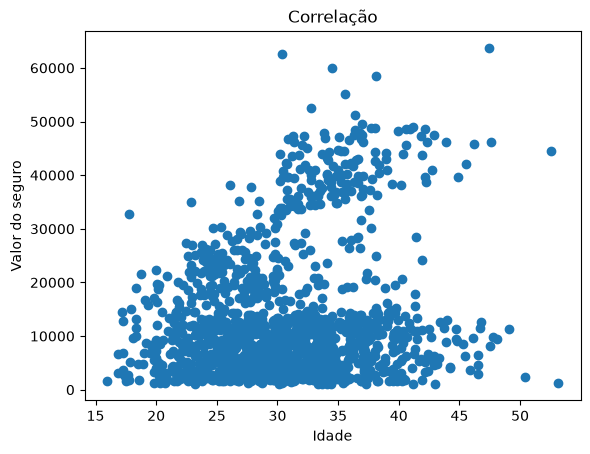

In [238]:

plt.scatter(df.bmi, df.charges)
plt.title('Correlação')
plt.xlabel('Idade')
plt.ylabel('Valor do seguro')
plt.grid(False)

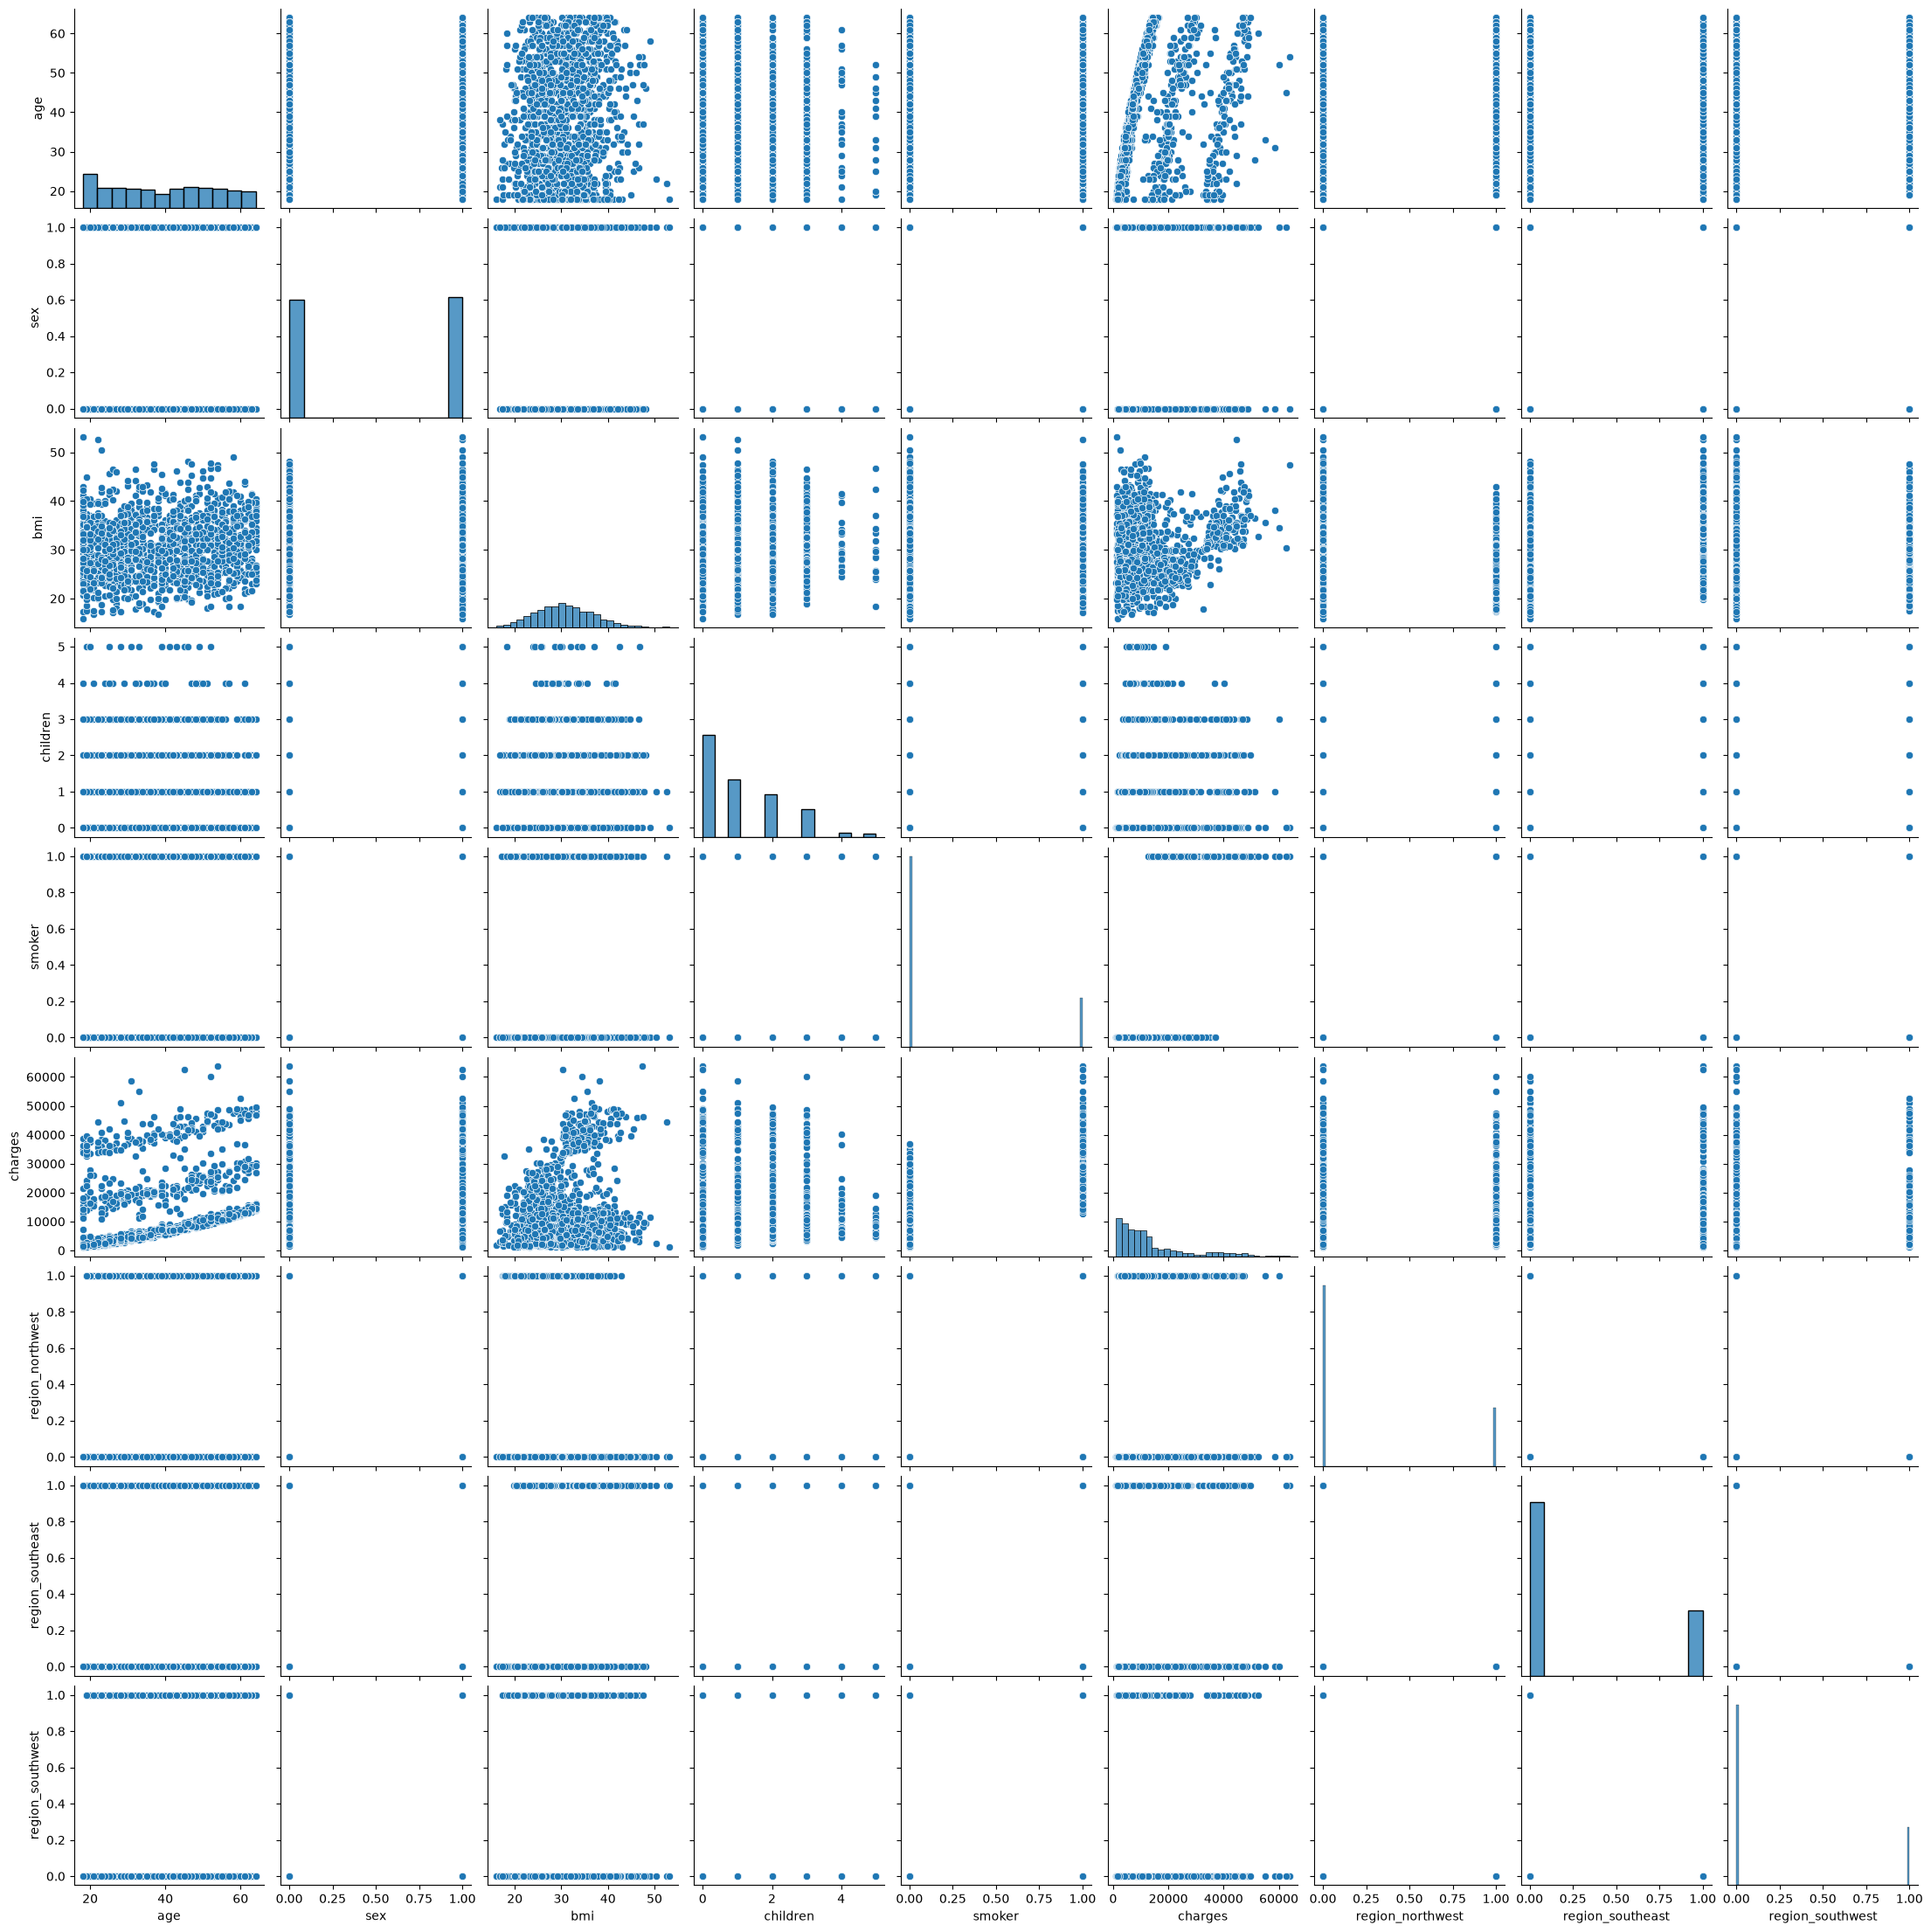

In [239]:
import seaborn as sns
sns.pairplot(df);

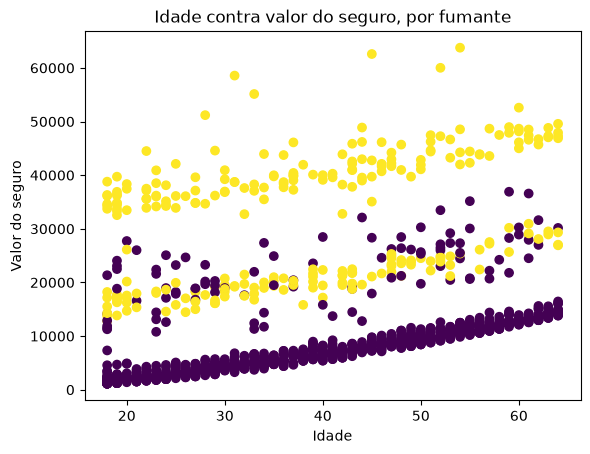

In [240]:
plt.scatter(df.age, df.charges, c=df.smoker)
plt.title('Idade contra valor do seguro, por fumante')
plt.xlabel('Idade')
plt.ylabel('Valor do seguro')
plt.grid(False)

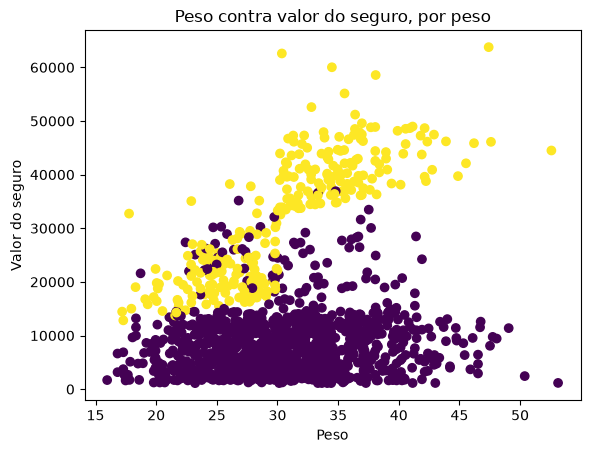

In [241]:
plt.scatter(df.bmi, df.charges, c=df.smoker)
plt.title('Peso contra valor do seguro, por peso')
plt.xlabel('Peso')
plt.ylabel('Valor do seguro')
plt.grid(False)

In [242]:
#ver que o bmi altera pesa mais com fumante, do que sozinho
fumantes = df[df.smoker == 1]
fumantes.groupby(fumantes.bmi >= 30).charges.mean()

bmi
False    21363.217016
True     41557.989840
Name: charges, dtype: float64

In [243]:
nao_fumantes = df[df.smoker == 0]
nao_fumantes.groupby(nao_fumantes.bmi >= 30).charges.mean()

bmi
False    7977.029520
True     8855.531349
Name: charges, dtype: float64

In [244]:
#histograma
hist = px.histogram(df, x='charges', nbins=60)
hist.update_layout(width=800, height=500, title_text='Distribuição de charges')
hist.show()

In [245]:
hist = px.histogram(df, x='age', nbins=60)
hist.update_layout(width=800, height=500, title_text='Distribuição de age')
hist.show()

In [246]:
hist = px.histogram(df, x='bmi', nbins=60)
hist.update_layout(width=800, height=500, title_text='Distribuição de bmi')
hist.show()

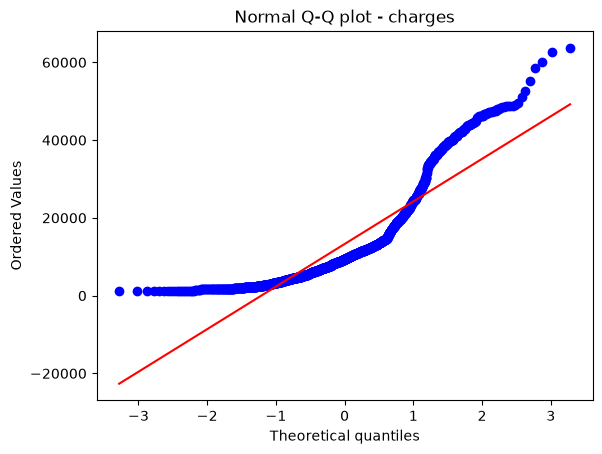

In [247]:
#Q-Q plot
import scipy.stats as stats
stats.probplot(df.charges, dist='norm', plot=plt)
plt.title('Normal Q-Q plot - charges')
plt.show()

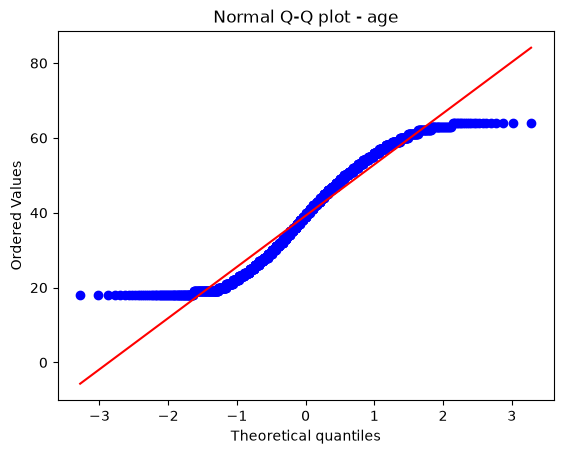

In [248]:
stats.probplot(df.age, dist='norm', plot=plt)
plt.title('Normal Q-Q plot - age')
plt.show()

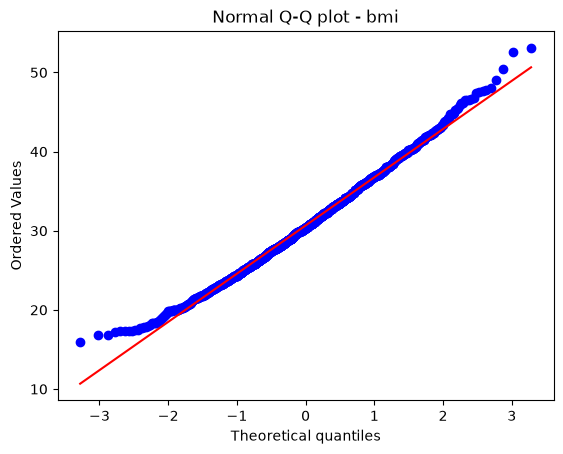

In [249]:
stats.probplot(df.bmi, dist='norm', plot=plt)
plt.title('Normal Q-Q plot - bmi')
plt.show()

In [250]:
#shapiro teste de nromalidade, p valor
estatistica, p = stats.shapiro(df.charges)
print('Estatistica do teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatistica do teste: 0.8147607892416321
p-valor: 1.1959741617198403e-36


In [251]:
estatistica, p = stats.shapiro(df.age)
print('Estatistica do teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatistica do teste: 0.9448560282004371
p-valor: 6.210451614246059e-22


In [252]:
estatistica, p = stats.shapiro(df.bmi)
print('Estatistica do teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatistica do teste: 0.993875513100442
p-valor: 2.5752925663935053e-05


In [253]:
correlacoes = df.corr(method='spearman')
correlacoes

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
age,1.000000,-0.019748,0.107897,0.055813,-0.025798,0.533523,0.004592,-0.015918,0.012667
sex,-0.019748,1.000000,0.044777,0.016372,0.076596,0.010748,-0.012482,0.017578,-0.003767
bmi,0.107897,0.044777,1.000000,0.015643,0.002216,0.119585,-0.127387,0.249121,0.001746
children,0.055813,0.016372,0.015643,1.000000,0.016199,0.132200,0.035902,-0.020029,0.011034
smoker,-0.025798,0.076596,0.002216,0.016199,1.000000,0.663611,-0.036321,0.068282,-0.037168
charges,0.533523,0.010748,0.119585,0.132200,0.663611,1.000000,-0.019546,0.016609,-0.043095
region_northwest,0.004592,-0.012482,-0.127387,0.035902,-0.036321,-0.019546,1.000000,-0.345909,-0.320493
region_southeast,-0.015918,0.017578,0.249121,-0.020029,0.068282,0.016609,-0.345909,1.000000,-0.346614
region_southwest,0.012667,-0.003767,0.001746,0.011034,-0.037168,-0.043095,-0.320493,-0.346614,1.000000


<Axes: >

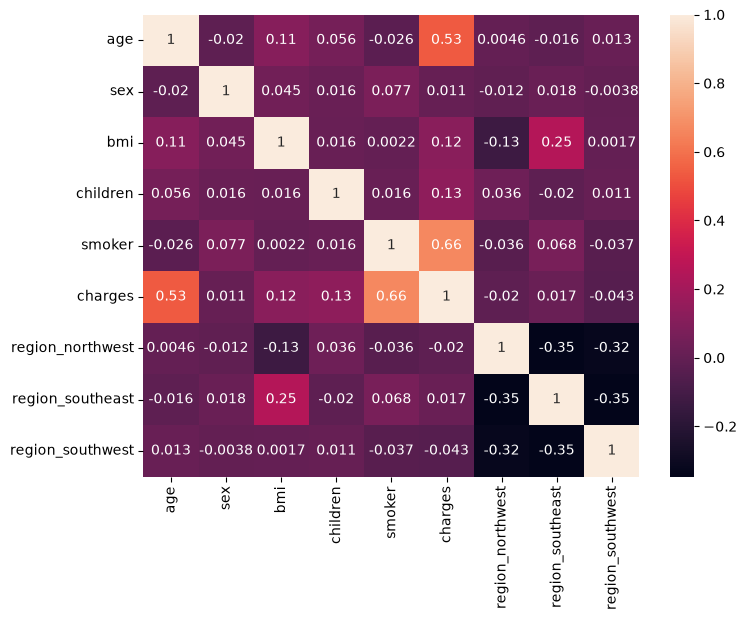

In [254]:
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(correlacoes, annot=True)

In [255]:
#vimos que idade e fumantes, pesa mais, agora vamos fazer a regressao deles

In [256]:
x_age = df[['age']]
y = df.charges
x_age.shape, y.shape

((1337, 1), (1337,))

In [257]:
from sklearn.model_selection import train_test_split
x_age_treino, x_age_teste, y_treino, y_teste = train_test_split(x_age, y, test_size=0.3, random_state=0)

In [258]:
x_age_treino.shape, y_treino.shape, x_age_teste.shape, y_teste.shape

((935, 1), (935,), (402, 1), (402,))

In [259]:
#regressão linear com age
from sklearn.linear_model import LinearRegression

In [260]:
age_linear = LinearRegression()
age_linear.fit(x_age_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[233.02]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,3892
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [261]:
age_linear.intercept_

np.float64(3891.8129516429835)

In [262]:
age_linear.coef_

array([233.02389044])

In [263]:
age_linear.score(x_age_treino, y_treino)

0.07682646420531714

In [264]:
age_linear.score(x_age_teste, y_teste)

0.10739068301367438

In [265]:
#treino
previsoes_treino = age_linear.predict(x_age_treino)
previsoes_treino

array([12979.74467862, 17407.19859688, 14144.86413079, 11581.601336  ,
        8086.24297948, 10416.48188383, 18106.27026819, 13445.79245949,
       16708.12692558, 14843.9358021 , 16475.10303514, 18572.31804906,
       11814.62522644, 14377.88802123,  8785.31465078, 17640.22248732,
        8785.31465078,  8319.26686991, 16009.05525427, 17407.19859688,
        8785.31465078, 17174.17470645,  8086.24297948, 12513.69689774,
       16941.15081601, 11581.601336  , 17174.17470645, 14610.91191166,
       16475.10303514,  9717.41021252, 11115.55355513, 13445.79245949,
       17873.24637775,  8086.24297948, 10649.50577426, 11348.57744557,
       13212.76856905,  9717.41021252,  8552.29076035, 12746.72078818,
       10183.45799339, 10416.48188383, 16009.05525427, 15309.98358297,
       15543.0074734 , 14610.91191166, 16009.05525427,  9018.33854122,
       13678.81634992, 11348.57744557, 18805.34193949, 17174.17470645,
       11115.55355513, 17640.22248732, 11814.62522644, 10183.45799339,
      

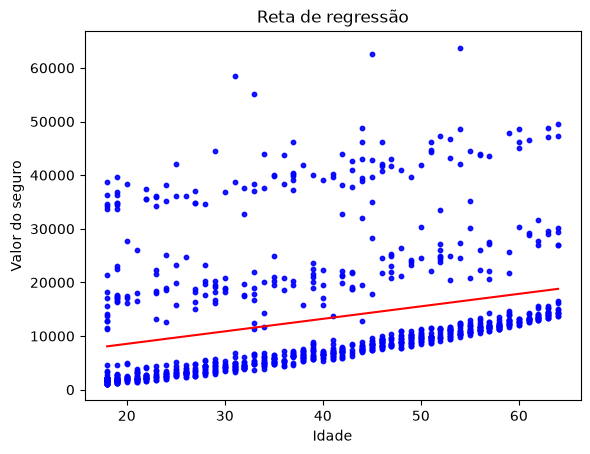

In [266]:
import matplotlib.pyplot as plt

plt.scatter(y=y_treino, x=x_age_treino, color='blue', s=10, alpha=0.9)
X_plot = np.linspace(18, 64)
plt.plot(X_plot, X_plot*age_linear.coef_ + age_linear.intercept_, color='r')
plt.title('Reta de regressão')
plt.ylabel('Valor do seguro')
plt.xlabel('Idade')
plt.show()

In [267]:
#teste
previsoes_teste = age_linear.predict(x_age_teste)
previsoes_teste

array([ 8086.24297948, 14843.9358021 , 15309.98358297,  8319.26686991,
       15776.03136384,  9950.43410296,  8086.24297948,  8319.26686991,
        8319.26686991, 17407.19859688, 15076.95969253,  9950.43410296,
       18572.31804906, 14144.86413079, 12280.67300731,  9251.36243165,
       12280.67300731,  9950.43410296, 12746.72078818, 18805.34193949,
        8086.24297948, 17873.24637775,  8319.26686991,  9018.33854122,
        9018.33854122, 11348.57744557, 10416.48188383, 15309.98358297,
       11115.55355513,  8552.29076035, 13212.76856905, 15776.03136384,
       16941.15081601, 16708.12692558,  9484.38632209, 18106.27026819,
       14610.91191166, 10416.48188383, 14843.9358021 ,  8552.29076035,
        8552.29076035, 10649.50577426,  9950.43410296, 17407.19859688,
        8086.24297948, 15309.98358297, 15543.0074734 , 13212.76856905,
       15776.03136384, 13212.76856905, 15776.03136384, 10882.5296647 ,
       15076.95969253, 10882.5296647 , 17407.19859688, 10183.45799339,
      

In [268]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

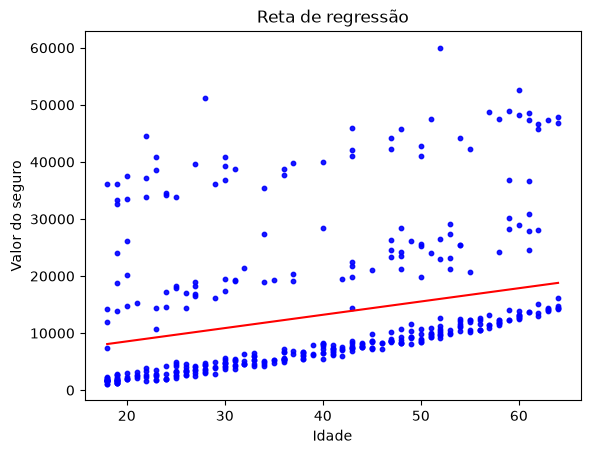

In [269]:
plt.scatter(y=y_teste, x=x_age_teste, color='blue', s=10, alpha=0.9)
X_plot = np.linspace(18, 64)
plt.plot(X_plot, X_plot*age_linear.coef_ + age_linear.intercept_, color='r')
plt.title('Reta de regressão')
plt.ylabel('Valor do seguro')
plt.xlabel('Idade')
plt.show()

In [270]:
valor_seguro = age_linear.predict([[52]])
valor_seguro

c:\Users\caioa\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([16009.05525427])

In [271]:
abs(y_teste - previsoes_teste).mean()

np.float64(9337.368443071615)

In [272]:
#agora ver as métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [273]:
mean_absolute_error(y_teste, previsoes_teste)

9337.368443071615

In [274]:
mean_squared_error(y_teste, previsoes_teste)

146173303.34737504

In [275]:
np.sqrt(mean_squared_error(y_teste, previsoes_teste))

np.float64(12090.215190284043)

In [276]:
#validação cruada age
from sklearn.model_selection import KFold, cross_validate

In [277]:
Kfold = KFold(n_splits=10, shuffle=True, random_state=0)

In [278]:
modelo = LinearRegression()

In [279]:
resultado = cross_validate(modelo, x_age_treino, y_treino, cv=Kfold, scoring='r2', return_train_score=True)

In [280]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.07690673789555487
R² teste (média): 0.06673285302380946


In [281]:
#fazer com a outra variavel que pesa, que é dos fumantes

In [282]:
x_smoker = df[['smoker']]
y = df.charges
x_smoker.shape, y.shape

((1337, 1), (1337,))

In [283]:
x_smoker_treino, x_smoker_teste, y_treino, y_teste = train_test_split(x_smoker, y, test_size=0.3, random_state=0)

In [284]:
smoker_linear = LinearRegression()
smoker_linear.fit(x_smoker_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[23220.46]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['smoker']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8394
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [285]:
smoker_linear.intercept_

np.float64(8393.80976951806)

In [286]:
smoker_linear.coef_

array([23220.4579549])

In [287]:
smoker_linear.score(x_smoker_treino, y_treino)

0.6231496461001471

In [288]:
previsoes_treino = smoker_linear.predict(x_smoker_treino)
previsoes_treino

array([ 8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952, 31614.26772441,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
       31614.26772441,  8393.80976952, 31614.26772441, 31614.26772441,
        8393.80976952, 31614.26772441,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952, 31614.26772441, 31614.26772441,
       31614.26772441,  8393.80976952, 31614.26772441,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
       31614.26772441,  8393.80976952,  8393.80976952,  8393.80976952,
       31614.26772441,  8393.80976952, 31614.26772441,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
      

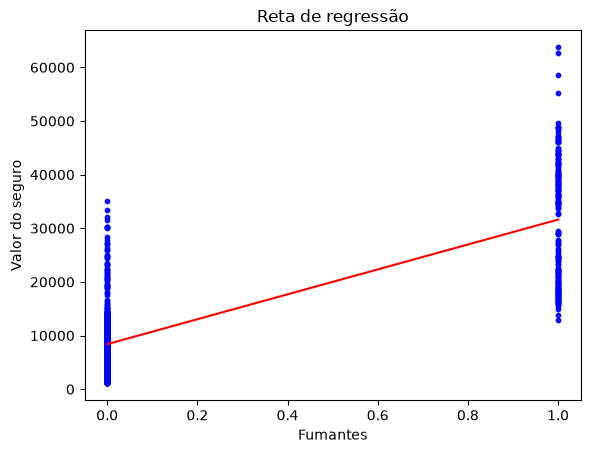

In [289]:
plt.scatter(y=y_treino, x=x_smoker_treino, color='blue', s=10, alpha=0.9)
X_plot = np.linspace(0, 1)
plt.plot(X_plot, X_plot*smoker_linear.coef_ + smoker_linear.intercept_, color='r')
plt.title('Reta de regressão')
plt.ylabel('Valor do seguro')
plt.xlabel('Fumantes')
plt.show()

In [290]:
#teste
previsoes_teste = smoker_linear.predict(x_smoker_teste)
previsoes_teste

array([ 8393.80976952,  8393.80976952,  8393.80976952, 31614.26772441,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952, 31614.26772441,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952, 31614.26772441,  8393.80976952, 31614.26772441,
        8393.80976952,  8393.80976952, 31614.26772441,  8393.80976952,
        8393.80976952, 31614.26772441,  8393.80976952,  8393.80976952,
       31614.26772441,  8393.80976952,  8393.80976952, 31614.26772441,
       31614.26772441,  8393.80976952,  8393.80976952,  8393.80976952,
        8393.80976952,  8393.80976952, 31614.26772441,  8393.80976952,
       31614.26772441, 31614.26772441,  8393.80976952,  8393.80976952,
      

In [291]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [292]:
smoker_linear.score(x_smoker_teste, y_teste)

0.6113351239111664

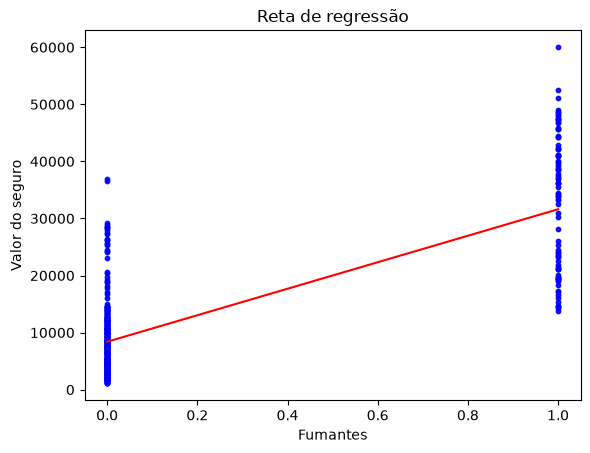

In [293]:
plt.scatter(y=y_teste, x=x_smoker_teste, color='blue', s=10, alpha=0.9)
X_plot = np.linspace(0, 1)
plt.plot(X_plot, X_plot*smoker_linear.coef_ + smoker_linear.intercept_, color='r')
plt.title('Reta de regressão')
plt.ylabel('Valor do seguro')
plt.xlabel('Fumantes')
plt.show()

In [294]:
valor_seguro = smoker_linear.predict([[0]])
valor_seguro

c:\Users\caioa\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([8393.80976952])

In [295]:
abs(y_teste - previsoes_teste).mean()

np.float64(5978.59801649322)

In [296]:
#métricas
mean_absolute_error(y_teste, previsoes_teste)

5978.59801649322

In [297]:
mean_squared_error(y_teste, previsoes_teste)

63647586.63377623

In [298]:
np.sqrt(mean_squared_error(y_teste, previsoes_teste))

np.float64(7977.943759752649)

In [299]:
#validação cruzada smoker
from sklearn.model_selection import KFold, cross_validate

In [300]:
Kfold = KFold(n_splits=10, shuffle=True, random_state=0)

In [301]:
modelo = LinearRegression()

In [302]:
resultado = cross_validate(modelo, x_smoker_treino, y_treino, cv=Kfold, scoring='r2', return_train_score=True)

In [303]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.6232524786280996
R² teste (média): 0.616136109871673


In [304]:
#statsmodels
import statsmodels.formula.api as smf

In [305]:
regressao_age = smf.ols('charges ~ age', data=df).fit()

In [306]:
residuos_age = regressao_age.resid
residuos_age

0        8807.537646
1       -6094.604336
2       -5942.991812
3       10305.868211
4       -7554.517482
            ...     
1333    -5450.959297
1334    -5614.175836
1335    -6190.323136
1336    -6583.900789
1337    10260.325810
Length: 1337, dtype: float64

In [307]:
estatisitica, p = stats.shapiro(residuos_age)
print('Estatistica do teste: {}'.format(estatisitica))
print('p-valor: {}'.format(p))

Estatistica do teste: 0.6580346965892955
p-valor: 1.312040251436056e-45


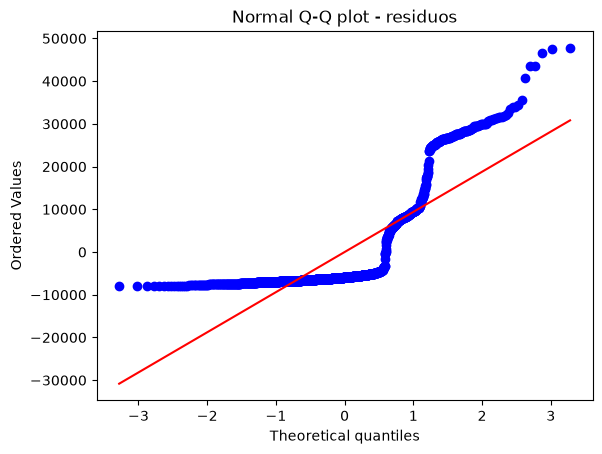

In [308]:
stats.probplot(residuos_age, dist="norm", plot=plt)
plt.title('Normal Q-Q plot - residuos')
plt.show()

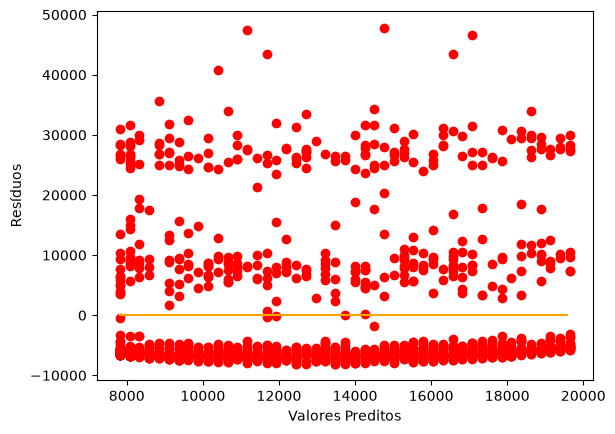

In [309]:
plt.scatter(y=residuos_age,x=regressao_age.predict(),color='red')
plt.hlines(y=0,xmin=7800,xmax=19600,color='orange')
plt.ylabel('Resíduos')
plt.xlabel('Valores Preditos')
plt.show()

In [310]:
from statsmodels.compat import lzip
import statsmodels.stats.api as sms

In [311]:
estatisitica, p ,f,fp = sms.het_breuschpagan(regressao_age.resid, regressao_age.model.exog)
print('Estatistica do teste: {}'.format(estatisitica))
print('p-valor: {}'.format(p))
print('f-valor: {}'.format(f))
print('f-p-valor: {}'.format(fp))

Estatistica do teste: 0.0011201437015326832
p-valor: 0.9733009468780883
f-valor: 0.0011184690309313922
f-p-valor: 0.9733259044445468


In [312]:
outliers = regressao_age.outlier_test()
outliers

,student_resid,unadj_p,bonf(p)
0,0.762438,0.445933,1.0
1,-0.527571,0.597885,1.0
2,-0.514127,0.607249,1.0
3,0.891587,0.372775,1.0
4,-0.653487,0.513555,1.0
...,...,...,...
1333,-0.471545,0.637329,1.0
1334,-0.485975,0.627064,1.0
1335,-0.535858,0.592146,1.0
1336,-0.569807,0.568904,1.0


In [313]:
outliers.max()

student_resid    4.163193
unadj_p          0.999243
bonf(p)          1.000000
dtype: float64

In [314]:
outliers.min()

student_resid   -0.697467
unadj_p          0.000033
bonf(p)          0.044649
dtype: float64

In [315]:
coefs = pd.DataFrame(regressao_age.params)
coefs.columns = ['Coeficientes']
print(coefs)

           Coeficientes
Intercept   3190.021721
age          257.229718


In [316]:
regressao_age.predict()

array([ 8077.38635387,  7820.15663635, 10392.45381153, ...,
        7820.15663635,  8591.84578891, 18881.03448962], shape=(1337,))

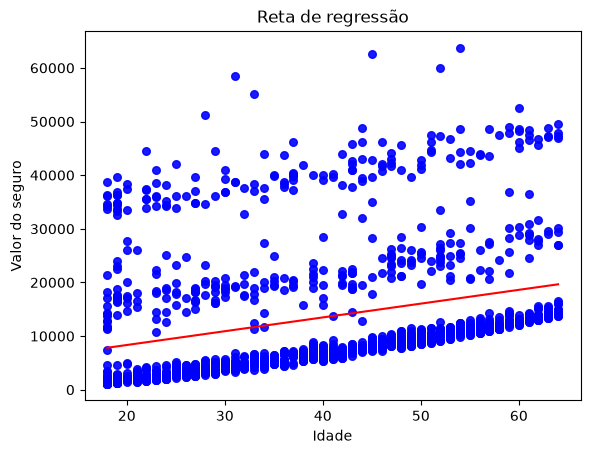

In [317]:
plt.scatter(y=df.charges, x=df.age, color='blue', s=30, alpha=0.9)
x_plot = np.linspace(18, 64)
plt.plot(x_plot, x_plot*regressao_age.params.iloc[1] + regressao_age.params.iloc[0], color='r')
plt.title('Reta de regressão')
plt.ylabel('Valor do seguro')
plt.xlabel('Idade')
plt.show()

In [318]:
#completamos a regressão simples, com as principais variaveis em relção a mudança do valor do seguro
#| | age | smoker |
#|---|---|---|
#| R² treino | 0,085 | 0,633 |
#| R² teste | 0,097 | 0,584 |
#| R² validação cruzada (teste) | ~0,067 | 0,617 |
#| Erro absoluto médio | 8.728 | 5.701 |
#| Raiz do erro quadrático | 10.943 | 7.432 |

In [319]:
#agora vamos seguir para a regressão multipla

In [320]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges
X.shape, y.shape

((1337, 3), (1337,))

In [321]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [322]:
multipla = LinearRegression()
multipla.fit(X_treino, y_treino)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 244.7 ,23659.92, 284.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['age','smoker','bmi']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.008e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [323]:
multipla.intercept_

np.float64(-10081.065901044913)

In [324]:
multipla.coef_

array([  244.70301452, 23659.92317363,   284.07452881])

In [325]:
print(f'Equação = {multipla.intercept_:.2f} + ({multipla.coef_[0]:.2f})*age + {multipla.coef_[1]:.2f}*smoker + {multipla.coef_[2]:.2f}*bmi')

Equação = -10081.07 + (244.70)*age + 23659.92*smoker + 284.07*bmi


In [326]:
multipla.score(X_treino, y_treino)

0.7386718262322491

In [327]:
previsoes_teste = multipla.predict(X_teste)
previsoes_teste

array([ 5635.43609763,  9763.24469252, 10815.1182886 , 26821.46904503,
        7526.33308441,  1300.80940054,  1799.009586  ,   192.96704529,
        1881.79011909, 14474.74775207, 10507.91887775, 27628.19239973,
       14267.94757208,  9154.12844165,  6085.77291785,  9858.7781945 ,
        6365.58632873,  5510.79391756,  3994.36185261, 14944.44387039,
        3229.32483858, 12754.05394693,  3204.15705072,  4208.13689665,
        4895.59725638,  8355.35309677,  1682.26710862, 10971.35927945,
        4816.80592065, 28593.07265192,  7857.15291131, 38245.50829907,
        9900.34999869, 13973.57982215, 25280.93895226, 14314.02202986,
       12018.39753157, 30770.85452789,  6979.31431014,  4272.6761988 ,
       27189.74447958,  4952.36385501,  4620.22026973, 38269.60632689,
       28451.65792069, 12377.52819708, 10059.8789617 ,  9081.5141305 ,
       13619.73172747,  6156.96685635, 33102.33895489,  5194.22612424,
       33278.68877619, 32013.05805828, 16017.27244353,  3920.37547594,
      

In [328]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [329]:
multipla.score(X_teste, y_teste)

0.7606965669130696

In [330]:
valor_seguro = multipla.predict([[40, 1, 30]])
valor_seguro

c:\Users\caioa\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([31889.21371768])

In [331]:
abs(y_teste - previsoes_teste).mean()

np.float64(4222.571855902198)

In [332]:
#metricas
mean_squared_error(y_teste, previsoes_teste)

39188223.39294493

In [333]:
np.sqrt(mean_squared_error(y_teste, previsoes_teste))

np.float64(6260.049791570746)

In [334]:
#comparando com a simples
#age	smoker	múltipla
#absoluto médio	8.728	5.701	4.035
#quadrático médio	119.742.394	55.230.104	36.689.950
#Raiz do erro quadrático	10.943	7.432	6.057

In [335]:
#validação cruada
kfold = KFold(n_splits=10, shuffle=True, random_state=0)

In [336]:
modelo = LinearRegression()

In [337]:
resultado = cross_validate(modelo, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

In [338]:
#resultado
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.7388619735987451
R² teste (média): 0.729685026172756


In [339]:
## | | age | smoker | múltipla |
# |---|---|---|---|
# | R² treino | 0,085 | 0,633 | 0,755 |
# | R² teste | 0,097 | 0,584 | 0,723 |
# | R² validação cruzada (teste) | ~0,067 | 0,617 | 0,743 |
# | Erro absoluto médio | 8.728 | 5.701 | 4.035 |
# | Raiz do erro quadrático | 10.943 | 7.432 | 6.057 |

In [340]:
#stats models
modelo_multipla = smf.ols('charges ~ age + smoker + bmi', data=df).fit()

In [341]:
residuos_multipla = modelo_multipla.resid
residuos_multipla

0       -9196.486571
1       -2168.155411
2       -1790.123095
3       17769.334815
4       -2081.167325
            ...     
1333     -691.559132
1334    -1090.838134
1335    -3257.613365
1336      -92.594981
1337    -8213.653217
Length: 1337, dtype: float64

In [342]:
estatistica, p = stats.shapiro(residuos_multipla)
print('Estatistica do teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))

Estatistica do teste: 0.9031985360803635
p-valor: 2.838470731156176e-28


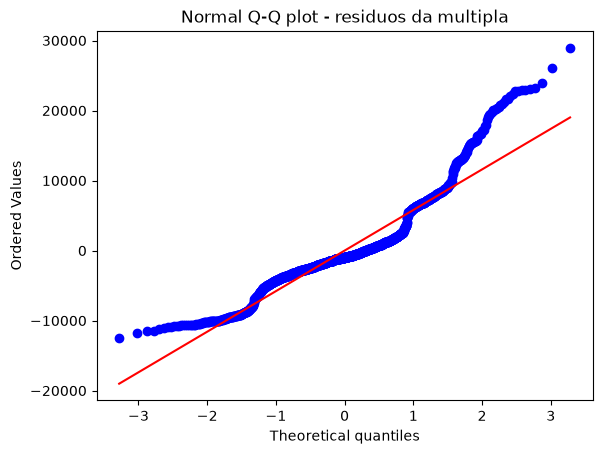

In [343]:
stats.probplot(residuos_multipla, dist="norm", plot=plt)
plt.title('Normal Q-Q plot - residuos da multipla')
plt.show()

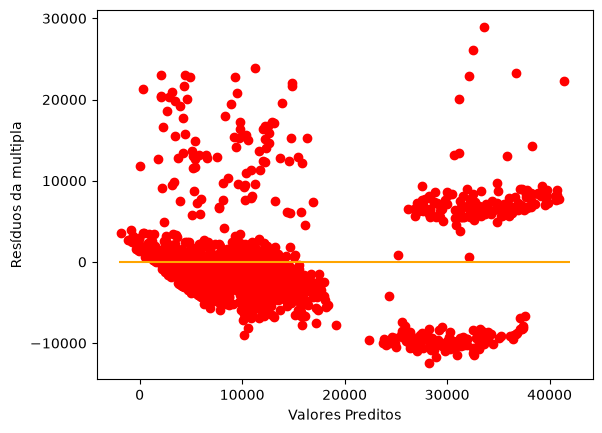

In [344]:
plt.scatter(y=residuos_multipla,x=modelo_multipla.predict(),color='red')
plt.hlines(y=0,xmin=-2000,xmax=42000,color='orange')
plt.ylabel('Resíduos da multipla')
plt.xlabel('Valores Preditos')
plt.show()

In [345]:
estatistica, p, f, fp = sms.het_breuschpagan(modelo_multipla.resid, modelo_multipla.model.exog)
print('Estatistica do teste: {}'.format(estatistica))
print('p-valor: {}'.format(p))
print('f-valor: {}'.format(f))
print('f-p-valor: {}'.format(fp))

Estatistica do teste: 112.59028476502603
p-valor: 3.0396809659789005e-24
f-valor: 40.85855895139847
f-p-valor: 2.9335053179686025e-25


In [346]:
outliers = modelo_multipla.outlier_test()

In [347]:
outliers.max()

student_resid    4.802264
unadj_p          0.999143
bonf(p)          1.000000
dtype: float64

In [348]:
outliers.min()

student_resid   -2.045999
unadj_p          0.000002
bonf(p)          0.002335
dtype: float64

In [349]:
#correlação entre as variáveis explicativas
variaveis = df[['age', 'smoker', 'bmi']]
correlacoes = variaveis.corr(method='pearson')
correlacoes

,age,smoker,bmi
age,1.000000,-0.025587,0.109344
smoker,-0.025587,1.000000,0.003746
bmi,0.109344,0.003746,1.000000


In [350]:
print(modelo_multipla.summary())

                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.747
Model:                            OLS   Adj. R-squared:                  0.747
Method:                 Least Squares   F-statistic:                     1314.
Date:                Tue, 03 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:13:24   Log-Likelihood:                -13547.
No. Observations:                1337   AIC:                         2.710e+04
Df Residuals:                    1333   BIC:                         2.712e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.167e+04    938.136    -12.441      0.0

In [351]:
df['previsoes_multipla'] = modelo_multipla.fittedvalues

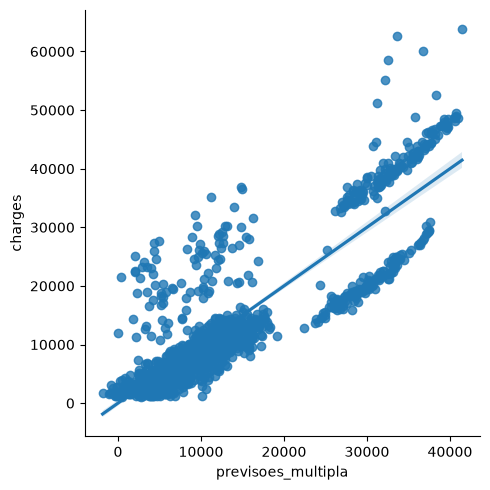

In [352]:
sns.lmplot(x='previsoes_multipla', y='charges', data=df)
plt.show()

In [353]:
#regressão com SVR
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler

In [354]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [355]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [356]:
#com 5 splits
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [357]:
x_scaler = StandardScaler()
X_treino_scaler = x_scaler.fit_transform(X_treino)

In [358]:
y_scaler = StandardScaler()
y_treino_scaler = y_scaler.fit_transform(y_treino.values.reshape(-1, 1))

In [359]:
modelo = SVR(kernel='rbf')

In [360]:
resultado = cross_validate(modelo, X_treino_scaler, y_treino_scaler.ravel(), cv=kfold, scoring='r2', return_train_score=True)

In [361]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.8437082642470715
R² teste (média): 0.837502748683481


In [362]:
SVR = SVR(kernel='rbf')
SVR.fit(X_treino_scaler, y_treino_scaler)

c:\Users\caioa\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [363]:
SVR.score(X_treino_scaler, y_treino_scaler)

0.8439077182828265

In [364]:
X_teste_scaler = x_scaler.transform(X_teste)
y_teste_scaler = y_scaler.transform(y_teste.values.reshape(-1, 1))

In [365]:
SVR.score(X_teste_scaler, y_teste_scaler.ravel())

0.8504860664426769

In [366]:
previsoes_teste = SVR.predict(X_teste_scaler)

In [367]:
y_teste_inverse = y_scaler.inverse_transform(y_teste_scaler)
previsoes_inverse = y_scaler.inverse_transform(previsoes_teste.reshape(-1,1))

In [368]:
mean_absolute_error(y_teste_inverse, previsoes_inverse)

2398.9262549267764

In [369]:
mean_squared_error(y_teste_inverse, previsoes_inverse)

24484335.026125062

In [370]:
np.sqrt(mean_squared_error(y_teste_inverse, previsoes_inverse))

np.float64(4948.16481396134)

In [371]:
#arvore de decisão
from sklearn.tree import DecisionTreeRegressor

In [372]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [373]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [374]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [375]:
arvore = DecisionTreeRegressor(max_depth=4, random_state=0)

In [376]:
resultado = cross_validate(arvore, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

In [377]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.8678542782920114
R² teste (média): 0.8478069480642567


In [378]:
arvore = DecisionTreeRegressor(max_depth=4, random_state=0)
arvore.fit(X_treino, y_treino)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_

In [379]:
arvore.score(X_treino, y_treino)

0.8664935108120123

In [380]:
arvore.score(X_teste, y_teste)

0.8467287432285779

In [381]:
previsoes_teste = arvore.predict(X_teste)
previsoes_teste

array([ 4082.02478459, 10363.88911342, 10363.88911342, 35398.15447409,
       10363.88911342,  5648.6578276 ,  2193.5047475 ,  2193.5047475 ,
        2193.5047475 , 12981.99826844, 10363.88911342, 19717.51916333,
       15331.431309  , 10363.88911342,  6979.83360083,  5648.6578276 ,
        6979.83360083,  5648.6578276 ,  6979.83360083, 15331.431309  ,
        4082.02478459, 12981.99826844,  4082.02478459,  4082.02478459,
        4082.02478459,  5648.6578276 ,  5648.6578276 , 10363.88911342,
        5648.6578276 , 35398.15447409,  6979.83360083, 47302.98001667,
       12981.99826844, 12981.99826844, 19717.51916333, 12981.99826844,
        8992.10528148, 35398.15447409, 10363.88911342,  4082.02478459,
       35398.15447409,  5648.6578276 ,  5648.6578276 , 47302.98001667,
       35398.15447409,  8992.10528148, 10363.88911342,  6979.83360083,
        8992.10528148,  6979.83360083, 23699.2900185 ,  5648.6578276 ,
       27540.9449805 , 47302.98001667, 12981.99826844,  5648.6578276 ,
      

In [382]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [383]:
mean_absolute_error(y_teste, previsoes_teste)

2943.6540225009862

In [384]:
mean_squared_error(y_teste, previsoes_teste)

25099632.598643057

In [385]:
np.sqrt(mean_squared_error(y_teste, previsoes_teste))

np.float64(5009.953352940829)

In [386]:
#random faroest
from sklearn.ensemble import RandomForestRegressor

In [387]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [388]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [389]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [390]:
random_forest = RandomForestRegressor(n_estimators=60, criterion='squared_error', max_depth=4, random_state=0)

In [391]:
resultado = cross_validate(random_forest, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

In [392]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.8726699847231731
R² teste (média): 0.8491609544974983


In [393]:
random = RandomForestRegressor(n_estimators=60, criterion='squared_error', max_depth=4, random_state=0)
random.fit(X_treino, y_treino)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",60
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the

In [394]:
random.score(X_treino, y_treino)

0.8698398093604912

In [395]:
random.score(X_teste, y_teste)

0.8572292331005976

In [396]:
previsoes_teste = random.predict(X_teste)
previsoes_teste

array([ 3942.88893017, 10456.26569173, 10082.64276908, 35233.06554384,
       10655.95084341,  6677.39156293,  2952.0050607 ,  2871.20693776,
        2952.0050607 , 12990.93519945, 10109.79819221, 18227.86574333,
       14487.6896144 ,  9423.00739391,  6416.06986007,  5566.16805948,
        6416.06986007,  5577.67223439,  7822.13393411, 14846.06925046,
        3826.4438366 , 13562.65186217,  3826.4438366 ,  4028.20942556,
        4121.40340551,  6301.20417121,  7386.35823968, 10082.64276908,
        6068.40680727, 36482.25446636,  6662.83968406, 45393.5965454 ,
       13076.54735347, 13169.70357808, 18060.01564378, 13562.65186217,
        9630.64544243, 36968.00802121, 10358.94888939,  4213.87274474,
       35794.43528606,  6156.49016975,  5595.71475677, 45446.16961642,
       36909.20131657,  9831.64530716, 10790.0088747 ,  6846.68527079,
        9991.3764157 ,  7222.20966321, 24170.77730955,  6090.80221015,
       27007.38460299, 41503.65631353, 13148.77924869,  5701.52961702,
      

In [397]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [398]:
#xgboost
from xgboost import XGBRegressor

In [399]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [400]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [401]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [402]:
xgboost = XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, objective='reg:squarederror', random_state=0)

In [403]:
resultado = cross_validate(xgboost, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

In [404]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.875300017650334
R² teste (média): 0.8516491176567407


In [405]:
xg = XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, objective='reg:squarederror', random_state=0)
xg.fit(X_treino, y_treino)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [406]:
xg.score(X_treino, y_treino)

0.8722918880468166

In [407]:
xg.score(X_teste, y_teste)

0.8616969054640296

In [408]:
previsoes_teste = xg.predict(X_teste)
previsoes_teste

array([ 3137.2007, 10192.406 , 10232.075 , 34862.703 , 10026.931 ,
        5062.498 ,  2728.971 ,  1915.4757,  2777.1062, 12848.461 ,
       10232.075 , 20040.543 , 14873.536 , 10091.631 ,  6409.7544,
        4637.6235,  6488.484 ,  5544.76  ,  6917.965 , 15220.545 ,
        3867.368 , 13956.728 ,  6096.157 ,  4071.0774,  3873.044 ,
        6188.3247,  6352.19  , 10232.075 ,  5757.0493, 36720.637 ,
        7466.2324, 45574.164 , 12310.867 , 13272.292 , 17567.783 ,
       13802.778 , 11482.703 , 38579.582 ,  8870.733 ,  3876.6904,
       35197.715 ,  6146.965 ,  5639.027 , 45086.652 , 36550.7   ,
       10267.465 , 10566.735 ,  7462.0093, 10080.653 ,  7860.863 ,
       25619.855 ,  6146.965 , 25749.12  , 40144.83  , 12696.777 ,
        5249.1113,  6142.7417, 10381.843 , 12574.34  , 45315.27  ,
       12085.916 , 15551.282 ,  6146.965 , 13848.362 ,  6052.6978,
        4777.1694,  1915.4757, 38146.082 ,  2352.1353,  7371.9653,
       43306.    ,  5728.1606,  6188.3247, 15399.783 , 13789.7

In [409]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [410]:
#lightgbm

In [411]:
import lightgbm as lgb

In [412]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [413]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [414]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [415]:
lightgbm = lgb.LGBMRegressor(num_leaves=30, max_depth=3, learning_rate=0.1, n_estimators=50, random_state=0)

In [416]:
resultado = cross_validate(lightgbm, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000739 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 298
[LightGBM] [Info] Number of data points in the train set: 748, number of used features: 3
[LightGBM] [Info] Start training from score 13226.794088
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

In [417]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.8760534576282645
R² teste (média): 0.8521435901341713


In [418]:
lgb = lgb.LGBMRegressor(num_leaves=50, max_depth=3, learning_rate=0.1, n_estimators=50, random_state=0)
lgb.fit(X_treino, y_treino)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000154 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 305
[LightGBM] [Info] Number of data points in the train set: 935, number of used features: 3
[LightGBM] [Info] Start training from score 13062.736068
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

,num_leaves,50
,max_depth,3
,n_estimators,50
,random_state,0
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [419]:
lgb.score(X_treino, y_treino)

0.8733803436257478

In [420]:
lgb.score(X_teste, y_teste)

0.8575938387846683

In [421]:
previsoes_teste = lgb.predict(X_teste)
previsoes_teste

array([ 2988.64311273, 10203.13185251, 10179.76280699, 34566.3389883 ,
       10538.03066852,  5507.90822889,  3313.9477067 ,  2473.49571913,
        3313.9477067 , 12552.36000167, 10179.76280699, 18781.62876839,
       15364.33915317,  9904.09381001,  6794.99254268,  4421.53582073,
        6869.59390849,  5570.52922826,  6524.33169153, 14894.18958091,
        4264.13386186, 14076.04650281,  4295.14184773,  4323.77535632,
        4308.77642888,  5754.81755279,  5997.51843232, 10179.76280699,
        6161.55273843, 35893.68634523,  7649.39553024, 46737.91218423,
       12294.01716187, 12793.31404732, 16812.92480853, 13645.71281532,
       11019.26623209, 37072.50596941,  9448.8378594 ,  4249.13493442,
       34535.33100243,  6289.40866039,  5799.79845696, 47208.4089905 ,
       37844.74885946, 10067.26581687, 10580.54583372,  7420.12630153,
       10035.85309504,  7672.14129177, 24232.72116159,  6289.40866039,
       26426.91131979, 43616.22446917, 12375.02935322,  5671.942535  ,
      

In [422]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [423]:
#catboost

In [424]:
from catboost import CatBoostRegressor

In [425]:
X = df[['age', 'smoker', 'bmi']]
y = df.charges

In [426]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0)
X_treino.shape, X_teste.shape, y_treino.shape, y_teste.shape

((935, 3), (402, 3), (935,), (402,))

In [427]:
kfold = KFold(n_splits=5, shuffle=True, random_state=0)

In [428]:
catboost = CatBoostRegressor(iterations=60, learning_rate=0.1, depth=6, random_state=0, verbose=0)

In [429]:
resultado = cross_validate(catboost, X_treino, y_treino, cv=kfold, scoring='r2', return_train_score=True)

In [430]:
print('R² treino (média):', resultado['train_score'].mean())
print('R² teste (média):', resultado['test_score'].mean())

R² treino (média): 0.8733082843640159
R² teste (média): 0.8501734802818032


In [431]:
cat = CatBoostRegressor(iterations=60, learning_rate=0.1, depth=6, random_state=0, verbose=0)
cat.fit(X_treino, y_treino)

CatBoostRegressor(depth=6, iterations=60, learning_rate=0.1, loss_function='RMSE', random_state=0, verbose=0)

In [432]:
cat.score(X_treino, y_treino)

np.float64(0.8683465610815615)

In [433]:
cat.score(X_teste, y_teste)

np.float64(0.8635542086542511)

In [434]:
previsoes_teste = cat.predict(X_teste)
previsoes_teste

array([ 3664.24386314, 10203.36662039, 10274.89509561, 29338.24138444,
       11272.1223452 ,  4951.72696672,  3619.171492  ,  2782.69827037,
        3433.65709673, 12960.25986313,  9786.32545555, 18702.21704763,
       14713.08058837,  9704.47511619,  6200.79649068,  3389.87366168,
        6297.15213437,  4837.7915553 ,  6411.88656074, 14785.53015829,
        4045.88110621, 13711.01524967,  4440.06943733,  4376.226804  ,
        4524.7654764 ,  6153.04628925,  5563.15934799, 10295.07741015,
        5960.09383081, 36477.37572458,  7539.48158437, 47508.86964957,
       12437.21260607, 13292.53784664, 17417.34025566, 13706.58409685,
       10253.61674664, 39211.51328342,  9591.64592633,  4176.73647593,
       30626.28031503,  6069.07116629,  5487.06376441, 46821.29066179,
       36512.27250022, 10438.57274152, 11313.91262449,  7342.6678413 ,
       11727.81298266,  7384.34911983, 23882.46130062,  5779.13942918,
       25459.15497853, 41940.78031082, 12556.82514446,  5477.18849742,
      

In [435]:
y_teste

1248     1633.96180
610      8547.69130
393      9290.13950
503     32548.34050
198      9644.25250
           ...     
1320     5425.02335
97      10226.28420
786     12741.16745
1181     2850.68375
1163     2200.83085
Name: charges, Length: 402, dtype: float64

In [442]:
#resultado dos algoritmos de regressão:
# | | age | smoker | múltipla | SVR | árvore | floresta | XGBoost | LightGBM | CatBoost |
# |---|---|---|---|---|---|---|---|---|---|
# | R² validação cruzada (treino) | 0,077 | 0,623 | 0,739 | 0,844 | 0,868 | 0,873 | 0,875 | 0,876 | 0,873 |
# | R² validação cruzada (teste) | 0,067 | 0,616 | 0,730 | 0,838 | 0,848 | 0,849 | 0,852 | 0,852 | 0,850 |
# | R² divisão única (teste) | 0,107 | 0,611 | 0,761 | 0,851 | 0,847 | 0,857 | 0,862 | 0,858 | 0,864 |

In [443]:
#O LightGBM teve o maior R² na validação cruzada (0,852), mas a diferença para os demais modelos de árvores e para o SVR é pequena e está dentro da variação entre as partes.

In [438]:
#considerando lightGBM 
import lightgbm as lgb

modelo_lgb = lgb.LGBMRegressor(num_leaves=50, max_depth=3, learning_rate=0.1, n_estimators=50, random_state=0)
modelo_lgb.fit(X_treino, y_treino)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000196 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 305
[LightGBM] [Info] Number of data points in the train set: 935, number of used features: 3
[LightGBM] [Info] Start training from score 13062.736068
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain,

,num_leaves,50
,max_depth,3
,n_estimators,50
,random_state,0
,boosting_type,'gbdt'
,learning_rate,0.1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


In [439]:
#criando paciente
pacientes = pd.DataFrame({'age': [40, 40], 'smoker': [0, 1], 'bmi': [32, 32]})
pacientes

,age,smoker,bmi
0,40,0,32
1,40,1,32


In [440]:
pacientes['previsao'] = modelo_lgb.predict(pacientes)
pacientes

,age,smoker,bmi,previsao
0,40,0,32,7420.126302
1,40,1,32,39399.714487


In [441]:
# em resumo previsão para dois pacientes (LightGBM)

#Dois pacientes com 40 anos e bmi 32, mudando só o hábito de fumar:

#Paciente A (não fumante):** previsão de cerca de 7.420.
#Paciente B (fumante):** previsão de cerca de 39.400, mais de 5 vezes maior.

#O fumo é o fator que mais pesa no valor do seguro, e o efeito é maior quando o bmi é alto acima de 30.